# v0 — minimal SQL agent: `generate_sql → execute_sql → answer`

Phase 1 prototype (vault: `01_Projects/ask-data/Tasks.md` → Phase 1). The smallest graph that turns a
question into SQL, runs it and answers, so we can **measure how it fails before adding defences**.

| In v0 | Deliberately *not* in v0 (Phase 2) |
|---|---|
| Typed `StateGraph` state beyond `messages` | `sql/guard.py` (sqlglot) + `EXPLAIN` cost cap |
| Structured output (`SqlDraft`, `FinalAnswer`) | Repair loop (`error` → retry `generate_sql`) |
| **Full schema** in the prompt, read from the catalog | `classify` / `decline`, clarification, follow-ups |
| Read-only tx + `statement_timeout` + `search_path` | `DatasetRegistry`, `notes.md`, few-shots |

Safety in v0 rests on the **database role** alone (`askdata_reader` is read-only and can only see dataset
schemas). That is layer 4 of 4 in the vault's defence-in-depth table — fine for a notebook, not for the API.

Everything dataset-specific comes from `datasets/<name>/` and the Postgres catalog. Switch `DATASET` to
`"sales"` and the same cells work unchanged.

## 1. Setup

`LLM_MODE`:
- `"auto"` (default): the real model in `LLM_MODEL` if its provider key is in `.env`, otherwise replay.
- `"real"`: always the real model (fails loudly without a key).
- `"replay"`: a **stand-in LLM that returns the golden SQL** for golden questions. It only proves the
  graph, DB plumbing and scoring work. Its "accuracy" means nothing; never report it.

In [24]:
import json
import os
import time
from datetime import UTC, datetime
from decimal import Decimal
from pathlib import Path
from typing import TypedDict

import psycopg
import yaml
from dotenv import load_dotenv
from psycopg import sql
from pydantic import BaseModel, Field

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
load_dotenv(ROOT / ".env")  # LangChain provider clients read their keys from os.environ
if not os.getenv("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "false"  # tracing on without a key only logs upload errors

from ask_data.config import settings
from ask_data.datasets.config import load_dataset_cfg

DATASET = "ipl"
LLM_MODE = os.getenv("V0_LLM_MODE", "auto")  # auto | real | replay
MAX_ROWS = settings.max_rows
ANSWER_ROWS = 20  # the answer node never sees more than this (vault gotcha #4)

cfg = load_dataset_cfg(ROOT / settings.datasets_dir / DATASET)
golden_path = ROOT / settings.datasets_dir / DATASET / "golden.yaml"
golden = yaml.safe_load(golden_path.read_text()) if golden_path.exists() else []
print(f"dataset={cfg.name} schema={cfg.schema_} tables={len(cfg.tables)} golden={len(golden)}")

dataset=ipl schema=ipl tables=6 golden=15


## 2. Schema context from the catalog

The prompt gets the **full schema** of the dataset (6 tables for IPL, so retrieval isn't needed yet;
that is Phase 3). It is read from Postgres, not from the yaml: the catalog is what the SQL will run
against, and the loader already wrote every yaml comment into it with `COMMENT ON`. So one function
works for any dataset.

In [25]:
SCHEMA_SQL = """
SELECT c.relname AS table_name, obj_description(c.oid, 'pg_class') AS table_comment,
       a.attname AS column_name, format_type(a.atttypid, a.atttypmod) AS data_type,
       col_description(c.oid, a.attnum) AS column_comment
FROM pg_class c
JOIN pg_namespace n ON n.oid = c.relnamespace
JOIN pg_attribute a ON a.attrelid = c.oid AND a.attnum > 0 AND NOT a.attisdropped
WHERE n.nspname = %(schema)s AND c.relkind = 'r'
ORDER BY c.relname, a.attnum
"""
KEYS_SQL = """
SELECT conrelid::regclass::text AS table_name, contype, pg_get_constraintdef(oid) AS definition
FROM pg_constraint
WHERE connamespace = %(schema)s::regnamespace AND contype IN ('p', 'f')
ORDER BY 1, 2 DESC, 3
"""


def schema_context(conn: psycopg.Connection, schema: str) -> str:
    # Render every table as a commented CREATE TABLE-like block, plus its PK / FKs.
    cols = conn.execute(SCHEMA_SQL, {"schema": schema}).fetchall()
    keys = conn.execute(KEYS_SQL, {"schema": schema}).fetchall()
    blocks: dict[str, list[str]] = {}
    for table, table_comment, column, dtype, comment in cols:
        if table not in blocks:
            header = f"-- {table_comment.strip()}" if table_comment else ""
            blocks[table] = (
                [header, f"TABLE {schema}.{table} ("] if header else [f"TABLE {schema}.{table} ("]
            )
        line = f"  {column} {dtype}"
        blocks[table].append(f"{line}  -- {comment}" if comment else line)
    for table, _contype, definition in keys:  # "PRIMARY KEY (id)", "FOREIGN KEY (x) REFERENCES ..."
        blocks[table.split(".")[-1]].append(f"  {definition}")
    return "\n\n".join("\n".join(lines) + "\n)" for lines in blocks.values())


with psycopg.connect(settings.reader_database_url) as conn:
    SCHEMA_CONTEXT = schema_context(conn, cfg.schema_)
print(
    SCHEMA_CONTEXT[:1500],
    "\n...",
    f"\n[{len(SCHEMA_CONTEXT):,} chars ≈ {len(SCHEMA_CONTEXT) // 4:,} tokens]",
)

-- One row per ball bowled (~300k rows). Legal ball = extras_type IS NULL OR extras_type NOT IN ('wides','noballs'). Innings 1 and 2 are the match; inning >= 3 is a super over.
TABLE ipl.deliveries (
  match_id bigint
  inning integer  -- 1 or 2; 3+ = super over (exclude with inning <= 2)
  over_no integer  -- 0-based over number: 0..19. Powerplay = 0..5, death overs = 15..19
  ball_no integer  -- Sequence within the over, counting wides and no-balls
  batting_team_id integer
  bowling_team_id integer
  batter_id integer
  bowler_id integer
  non_striker_id integer
  runs_batter integer  -- Runs off the bat
  runs_extras integer
  runs_total integer  -- runs_batter + runs_extras
  extras_type text  -- NULL | 'wides' | 'noballs' | 'byes' | 'legbyes' | 'penalty'
  is_wicket boolean
  wicket_kind text  -- caught | bowled | lbw | run out | stumped | caught and bowled | hit wicket | retired hurt | retired out | obstructing the field. Bowler's wicket excludes run out, retired hurt, retired o

## 3. State and structured outputs

The state is a `TypedDict` with real fields, not just `messages`: each node reads the keys it needs and
returns **only the keys it changes**, and LangGraph merges that partial update into the state.
`SqlDraft` / `FinalAnswer` are Pydantic models passed to `with_structured_output`, so the model has to
return a validated object (not free text we would have to regex the SQL out of).

In [26]:
class AskState(TypedDict, total=False):
    dataset: str
    question: str
    schema_context: str
    reasoning: str | None
    sql: str | None
    columns: list[str]
    rows: list[tuple]
    row_count: int
    error: str | None
    answer: str | None


class SqlDraft(BaseModel):
    reasoning: str = Field(description="1-3 sentences: which tables, joins and filters, and why")
    sql: str = Field(description="One PostgreSQL SELECT statement, no trailing semicolon")


class FinalAnswer(BaseModel):
    answer: str = Field(
        description="Direct answer in 1-3 sentences using only values from the rows"
    )

## 4. Prompts (domain-free)

Rules only. No dataset facts here: what "season" means or how a legal ball is defined comes from the
column comments in the schema block (and, from Phase 2, from `datasets/<name>/notes.md`).

In [27]:
SQL_SYSTEM_PROMPT = """You are an expert PostgreSQL analyst. Write ONE SQL query that answers the user's question.

Dataset: {title}
{description}

Schema (the only tables and columns that exist; comments explain meaning and units):
{schema}

Rules:
- PostgreSQL dialect. A single SELECT (CTEs allowed). No semicolon, no DDL/DML.
- Use only the tables and columns above. Schema-qualify tables ({schema_name}.table).
- Qualify columns with table aliases whenever more than one table is involved.
- Read the column comments: they define codes, units and how to count things correctly.
- Use ILIKE for free-text matching of names.
- For "top N" / "most" / "best" questions, ORDER BY the measure and LIMIT accordingly.
- Never SELECT *. Return only the columns needed to answer: the entity and the measure asked for.
- Return at most {max_rows} rows.
"""

ANSWER_PROMPT = """Question: {question}

SQL that was run:
{sql}

Result: {row_count} row(s); columns {columns}. First rows:
{rows}

Answer the question in 1-3 sentences. Use ONLY values present in the rows above; do not invent or
round numbers differently. If the result is empty, say that no matching data was found."""

## 5. The LLM (real, or replay for plumbing tests)

In [28]:
PROVIDER_KEYS = {
    "groq": "GROQ_API_KEY",
    "google_genai": "GOOGLE_API_KEY",
    "anthropic": "ANTHROPIC_API_KEY",
    "openai": "OPENAI_API_KEY",
}


def has_provider_key(model: str) -> bool:
    provider = model.split(":", 1)[0]
    return bool(os.getenv(PROVIDER_KEYS.get(provider, ""), ""))


class ReplayLLM:
    # Stand-in for a chat model: returns the golden SQL for golden questions. Plumbing only.
    def __init__(self, golden: list[dict]):
        self.gold = {q["question"]: q["gold_sql"] for q in golden if q.get("gold_sql")}

    def with_structured_output(self, schema):
        llm = self

        class _Runner:
            def invoke(self, prompt: str):
                if schema is SqlDraft:
                    question = prompt.rsplit("Question:", 1)[-1].strip()
                    sql_text = llm.gold.get(
                        question, "SELECT 'no replay SQL for this question' AS note"
                    )
                    return SqlDraft(reasoning="replay: golden SQL", sql=sql_text.strip())
                rows = prompt.split("First rows:", 1)[-1].split("Answer the question", 1)[0]
                return FinalAnswer(answer="(replay, no LLM) rows: " + rows.strip()[:200])

        return _Runner()


if LLM_MODE == "real" or (LLM_MODE == "auto" and has_provider_key(settings.llm_model)):
    from langchain.chat_models import init_chat_model

    llm = init_chat_model(settings.llm_model, temperature=0)
    MODE = f"real:{settings.llm_model}"
else:
    llm = ReplayLLM(golden)
    MODE = "replay (plumbing only — accuracy is meaningless)"

sql_llm = llm.with_structured_output(SqlDraft)
answer_llm = llm.with_structured_output(FinalAnswer)
print("LLM mode:", MODE)

LLM mode: real:groq:qwen/qwen3.8-27b


## 6. Nodes

`execute_sql` is where v0's only safety lives, so it is done properly even here:
`SET TRANSACTION READ ONLY` first, `SET LOCAL statement_timeout`, `SET LOCAL search_path` built with
`sql.Identifier` (never an f-string), and `fetchmany(MAX_ROWS)` so a huge result can't flood memory.
A failed query doesn't raise out of the graph: it is written to `error`, and the answer node reports it.
That `error` field is what Phase 2's repair loop will route on.

In [29]:
def generate_sql(state: AskState) -> dict:
    prompt = (
        SQL_SYSTEM_PROMPT.format(
            title=cfg.title,
            description=cfg.description.strip(),
            schema=state["schema_context"],
            schema_name=cfg.schema_,
            max_rows=MAX_ROWS,
        )
        + f"\nQuestion: {state['question']}"
    )
    try:
        draft = sql_llm.invoke(prompt)
    except Exception as e:  # noqa: BLE001 — provider/parse/validation errors (vault gotcha #6)
        return {
            "sql": None,
            "reasoning": None,
            "error": f"LLM did not return a valid SqlDraft: {e}",
        }
    return {"sql": draft.sql.strip().rstrip(";"), "reasoning": draft.reasoning, "error": None}


def execute_sql(state: AskState) -> dict:
    if state.get("error"):
        return {}
    try:
        with psycopg.connect(settings.reader_database_url) as conn, conn.transaction():
            conn.execute("SET TRANSACTION READ ONLY")
            conn.execute(
                sql.SQL("SET LOCAL statement_timeout = {}").format(
                    sql.Literal(settings.statement_timeout_ms)
                )
            )
            conn.execute(sql.SQL("SET LOCAL search_path = {}").format(sql.Identifier(cfg.schema_)))
            cur = conn.execute(state["sql"])
            columns = [c.name for c in cur.description or []]
            rows = cur.fetchmany(MAX_ROWS)
    except psycopg.Error as e:
        return {
            "error": f"{type(e).__name__}: {str(e).strip()}",
            "columns": [],
            "rows": [],
            "row_count": 0,
        }
    return {"columns": columns, "rows": rows, "row_count": len(rows), "error": None}


def answer(state: AskState) -> dict:
    if state.get("error"):
        return {"answer": f"Sorry, I could not answer that. {state['error']}"}
    preview = "\n".join(str(tuple(r)) for r in state["rows"][:ANSWER_ROWS])
    result = answer_llm.invoke(
        ANSWER_PROMPT.format(
            question=state["question"],
            sql=state["sql"],
            row_count=state["row_count"],
            columns=state["columns"],
            rows=preview or "(no rows)",
        )
    )
    return {"answer": result.answer}

## 7. The graph

Three nodes in a line. Phase 2 replaces the `execute_sql → answer` edge with conditional edges
(`ok` / `retry` / `give_up`) to get the self-correcting loop.

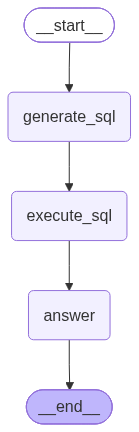

In [30]:
from IPython.core.display import Image
from langgraph.graph import END, START, StateGraph

builder = StateGraph(AskState)
builder.add_node("generate_sql", generate_sql)
builder.add_node("execute_sql", execute_sql)
builder.add_node("answer", answer)
builder.add_edge(START, "generate_sql")
builder.add_edge("generate_sql", "execute_sql")
builder.add_edge("execute_sql", "answer")
builder.add_edge("answer", END)
graph = builder.compile()

# graph image.
display(Image(graph.get_graph().draw_mermaid_png()))


def ask(question: str) -> AskState:
    return graph.invoke(
        {"dataset": cfg.name, "question": question, "schema_context": SCHEMA_CONTEXT}
    )

In [31]:
demo_q = golden[0]["question"] if golden else "How many rows are in the largest table?"
out = ask(demo_q)
print("Q:", demo_q, "\nSQL:", out["sql"], "\nrows:", out["rows"][:5], "\nA:", out["answer"])

Q: Who won the IPL final in 2016? 
SQL: SELECT t.name AS winner
FROM ipl.matches m
JOIN ipl.teams t ON t.id = m.winner_id
WHERE m.season = 2016
  AND m.stage = 'Final' 
rows: [('Sunrisers Hyderabad',)] 
A: Sunrisers Hyderabad won the IPL final in 2016.


## 8. Run the golden set and score it

**Execution match** (vault `Testing.md` → Metrics): run both SQLs and compare the result sets,
ignoring row and column order, rounding numbers to 2 dp and lower-casing text. Known limitation: extra
columns in the prediction count as a miss.

Every miss gets a *failure type* (filled in by hand after reading the SQL), which is the real output of
Phase 1: the list of things Phase 2 has to fix.

In [32]:
def _cell(v):
    if isinstance(v, bool):
        return str(v).lower()
    if isinstance(v, (int, float, Decimal)):
        return round(float(v), 2)
    return str(v).strip().lower()


def normalize(rows) -> list[tuple]:
    return sorted(tuple(sorted(map(str, map(_cell, r)))) for r in rows)


def execution_match(pred_rows, gold_rows) -> bool:
    return normalize(pred_rows) == normalize(gold_rows)


def run_gold(gold_sql: str) -> list[tuple]:
    with psycopg.connect(settings.reader_database_url) as conn, conn.transaction():
        conn.execute("SET TRANSACTION READ ONLY")
        return conn.execute(gold_sql).fetchall()


results = []
for q in golden:
    started = time.perf_counter()
    out = ask(q["question"])
    elapsed = time.perf_counter() - started
    gold_rows = run_gold(q["gold_sql"])
    match = not out.get("error") and execution_match(out["rows"], gold_rows)
    results.append(
        {
            "id": q["id"],
            "category": q["category"],
            "question": q["question"],
            "match": match,
            "error": out.get("error"),
            "pred_sql": out.get("sql"),
            "pred_rows": len(out.get("rows") or []),
            "gold_rows": len(gold_rows),
            "answer": out.get("answer"),
            "seconds": round(elapsed, 2),
            "failure_type": None,  # fill in by hand: wrong_join / wrong_filter / domain_rule / extra_columns / ...
        }
    )
    print(
        f"{'✅' if match else '❌'} {q['id']} [{q['category']:<12}] {elapsed:5.1f}s  {q['question']}"
    )
    print(f"   SQL:    {' '.join((out.get('sql') or '-').split())}")
    if out.get("error"):
        print(f"   Error:  {out['error']}")
    print(f"   Answer: {out.get('answer')}\n")

n_ok = sum(r["match"] for r in results)
print(
    f"\nmode={MODE}\nexecution accuracy: {n_ok}/{len(results)} = {n_ok / max(len(results), 1):.0%}"
    f" · SQL errors: {sum(bool(r['error']) for r in results)}"
)

✅ q001 [lookup      ]   1.1s  Who won the IPL final in 2016?
   SQL:    SELECT t.name AS winner FROM ipl.matches m JOIN ipl.teams t ON t.id = m.winner_id WHERE m.season = 2016 AND m.stage = 'Final'
   Answer: Sunrisers Hyderabad won the IPL final in 2016.

✅ q002 [lookup      ]   1.0s  At which venue was the first ever IPL match played?
   SQL:    SELECT v.name AS venue, v.city FROM ipl.matches m JOIN ipl.venues v ON v.id = m.venue_id ORDER BY m.match_date ASC LIMIT 1
   Answer: The first ever IPL match was played at M Chinnaswamy Stadium in Bengaluru.



KeyboardInterrupt: 

In [ ]:
for r in results:
    if not r["match"]:
        print(
            f"--- {r['id']} {r['question']}\nerror: {r['error']}\npred rows {r['pred_rows']} vs gold {r['gold_rows']}"
            f"\n{r['pred_sql']}\n"
        )

out_dir = ROOT / "evals" / "results"  # gitignored
out_dir.mkdir(parents=True, exist_ok=True)
out_file = out_dir / f"v0_{cfg.name}_{datetime.now(UTC):%Y%m%d_%H%M%S}.json"
out_file.write_text(
    json.dumps({"mode": MODE, "dataset": cfg.name, "results": results}, indent=2, default=str)
)
print("saved", out_file.relative_to(ROOT))

## 9. Failure types (fill in after a real-model run)

Copy the misses into vault `01_Projects/ask-data/Notes.md` → *Failure Patterns Log*, one line per
recurring pattern. Typical v0 categories to look for:

- **domain rule missed**: e.g. super overs counted, run-outs credited to the bowler, wides counted as balls
- **wrong entity grain**: grouped by `teams.name` when the question meant `franchise`, or by name instead of id
- **extra / missing columns**: right answer, but scored as a miss (metric limitation, not a model error)
- **wrong filter value**: `stage = 'final'` vs `'Final'`, a season stored as text, etc.
- **SQL error**: unknown column / bad join (what the Phase 2 repair loop exists for)